## Setting Up the Libs and Marmousi2 Configurations

In [1]:
from __future__ import print_function
import time
import torch
import torch.nn as nn
import numpy as np
import scipy.ndimage
import matplotlib
import matplotlib.pyplot as plt
import deepwave
import os
from timeit import default_timer as timer
import scipy.io as spio
import math
import numpy as np
from utils.utils import *
from torch import optim
from IPython.core.debugger import set_trace 
import random
from __future__ import print_function
torch.manual_seed(0)
random.seed(0)

####################################################
####   MAIN PARAMETERS FOR FORWARD MODELING         ####
####################################################

peak_freq = 6                    # central frequency
peak_source_time = 1 / peak_freq  # the time (in secs) of the peak amplitude
dx        = 20.0                  # step interval along x/z direction
dt        = 0.003                 # time interval (e.g., 3ms)
num_dims  = 2                     # dimension of velocity model
nz        = 117                   # model shape of z dimension (depth) Marmousi2
ny        = 567                   # model shape of y dimension Marmousi2
vmodel_dim = np.array([nz, ny])

total_t   = 6.                      # totle sampling time (unit: s)
nt        = int(total_t / dt)       # number of time sampling points
num_shots = 30                      # nunmber of shots
num_sources_per_shot = 1            # number of sources per shot
num_receivers_per_shot = 566        # number of receivers per shot
source_spacing = np.floor(dx * ny / (num_shots+1))                         # space intervel between neigbouring sources
receiver_spacing = np.floor(dx * ny / (num_receivers_per_shot +1))         # space intervel between neigbouring receivers
source_depth = 0                # the index depth of sources, default is 0
receiver_depth = 0              # the index depths of receivers, default is 0
order          = 8              # precision order of finite difference in space domain
pml_width  = [0,10,10,10]   # pml padding width for boundary (0 for free surface and 10 for absorbing boundary)

fwi_lr            = 20        # learning rate for updating the model.
fwi_batch         =   30      # number of batches for FWI.
fwi_num_epochs    = 200       # number of FWI iteration.
sim_lr            = 1e-3   # learning rate for Soamese network.
sim_lr1            = 1e-5   # learning rate for Soamese network.

survey_pad = None
savepoch = 20                 # Saving models each 50 FWI iterations


d_source = np.floor( dx*(ny / (num_shots+1)) )    # 20 * 4m = 80m
first_source = 18*dx  # 10 * 4m = 40m
source_depth = 0  # 2 * 4m = 8m

d_receiver = np.floor( dx*(ny / (num_receivers_per_shot)) )    # 6 * 4m = 24m
first_receiver = 0  # 0 * 4m = 0m
receiver_depth = 0  # 2 * 4m = 8m

##   Check Cuda Device 


In [2]:
torch.backends.cudnn.enabled = True
torch.backends.cudnn.benchmark = True

cuda_available = torch.cuda.is_available()
device = torch.device("cuda" if cuda_available else "cpu")
device 

device(type='cuda')

In [3]:
from deepwave import scalar
from scipy.ndimage import gaussian_filter
import torch
import numpy as np

data_path = 'data/mar_big_117_567.bin'
fwi_result = 'results/DIIP_Syn1/'

if not os.path.exists(fwi_result):
    # Create the directory
    os.makedirs(fwi_result)
    print(f"Directory '{fwi_result}' created.")
else:
    print(f"Directory '{fwi_result}' already exists.")
    
# Loading the true model
model_true = loadtruemodel(data_path, num_dims, vmodel_dim).to(device)
model_true = interp_depth_to_256(model_true, 256)


# The model will be updated during FWI
# move to numpy
model_np = model_true.detach().cpu().numpy()

# copy to avoid in-place modification
model_smooth = model_np.copy()

# indices of water layer
water_top = 0
water_bottom = 34  # excluded from smoothing

# apply smoothing ONLY below water layer
model_smooth= gaussian_filter(
    model_np,
    sigma=[30, 30]
)

# explicitly enforce water velocity (optional but recommended)
model_smooth[water_top:water_bottom, :] = 1500.0

# back to torch
model = torch.from_numpy(model_smooth).to(device)
model_init = torch.from_numpy(model_smooth).to(device)


model      = interp_depth_to_256(model,      256)
model_init = interp_depth_to_256(model_init, 256)
model = torch.nn.Parameter(model)

# Creating source and reciver locations
# x_s
x_s = torch.zeros(num_shots, num_sources_per_shot, 2,
                               dtype=torch.long, device=device)
x_s[:,0,0] = source_depth
x_s[:,0,1] = (torch.arange(num_shots) * d_source +
                             first_source)

# x_r
x_r = torch.zeros(num_shots, num_receivers_per_shot, 2,
                                 dtype=torch.long, device=device)
x_r[:,:,0] = receiver_depth
x_r[0,:,1] = (
    (torch.arange(num_receivers_per_shot) * d_receiver +
     first_receiver)
)
x_r[:, :, 1] = x_r[0, :, 1].repeat(num_shots, 1)

    
x_s = torch.floor(x_s/dx) 
x_r = torch.floor(x_r/dx) 

# source_amplitudes
source_amplitudes = (
    deepwave.wavelets.ricker(peak_freq, nt, dt, peak_source_time)
)

source = source_amplitudes.repeat(num_shots,num_sources_per_shot,1)
source_amplitudes_init = source

# receiver Amplitude
receiver_amplitudes_true = scalar(model_true.to(device), dx, dt, source_amplitudes=source.to(device),
                 source_locations=x_s.to(device),
                 receiver_locations=x_r.to(device),
                 accuracy=8,
                 pml_width=pml_width,
                 pml_freq = peak_freq)[-1]



# Mute Frequency below 3 Hz
receiver_amplitudes_true = highpass_filter(3, receiver_amplitudes_true.cpu(), dt=dt, pad=[10, 10, 0, 0, 0, 0]).to(device)

rcv_amps_true = receiver_amplitudes_true.clone()


Directory 'results/DIIP_Syn1/' already exists.


/home/sadalyom/.conda/envs/DAS_Denoising_Torch/lib/python3.8/site-packages/torch/cuda/__init__.py:611: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")


## Plotting the inital and true model


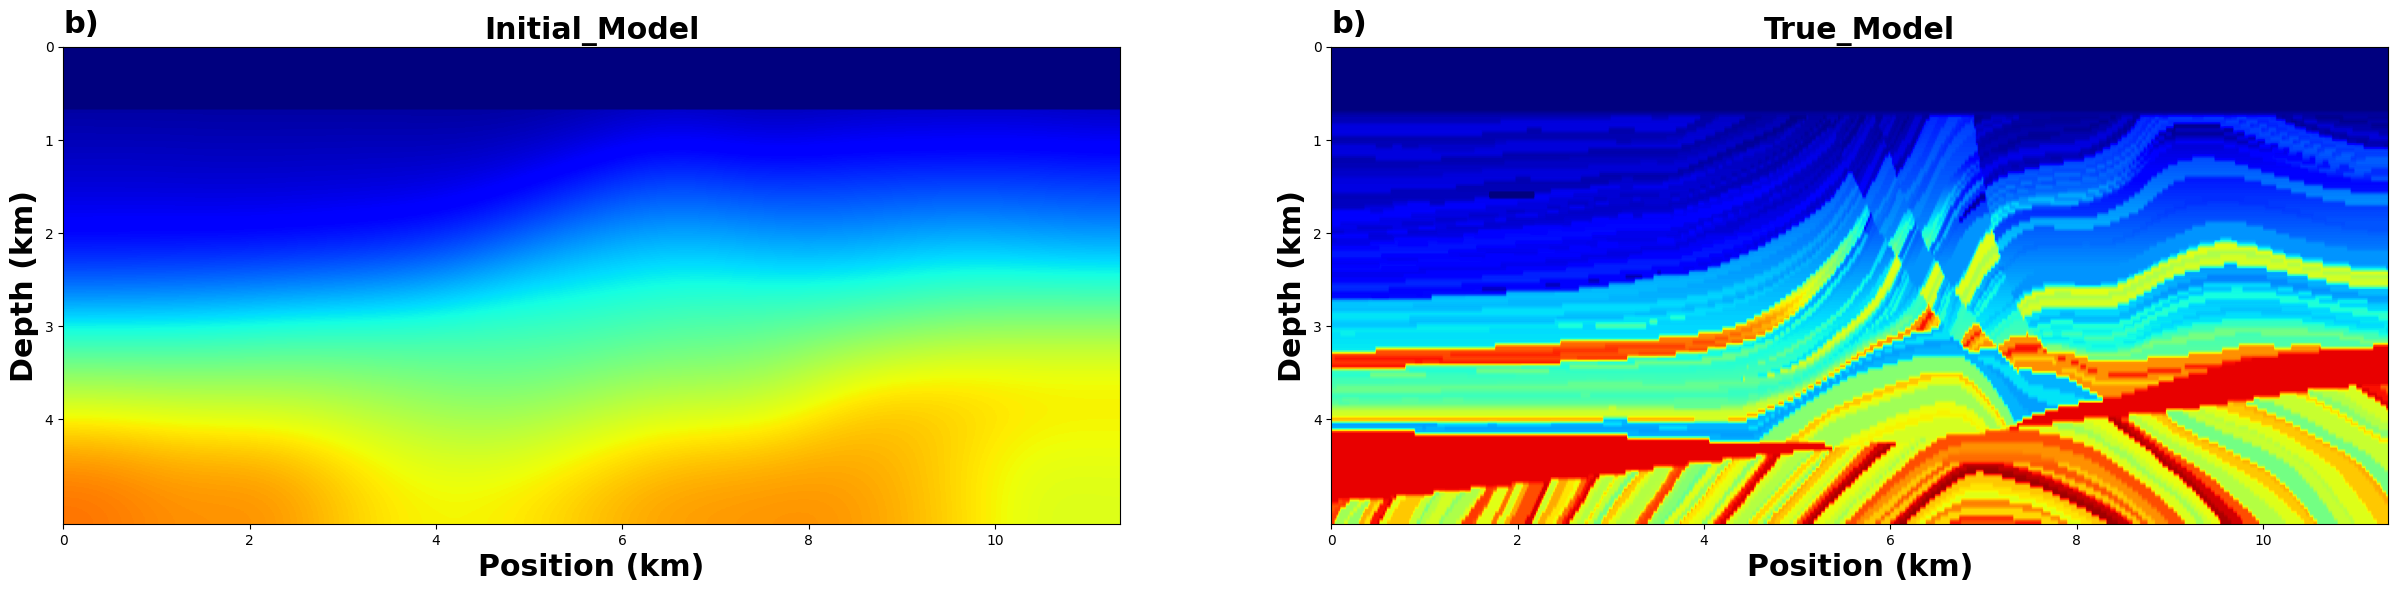

In [4]:
from matplotlib.ticker import MaxNLocator
import matplotlib.pyplot as plt
font = {
        'weight' : 'bold',
        'size'   : 18}

y = np.array([0, 1, 2, 3, 4, 5])
box_min = 1500
box_max = 4800

f, ax = plt.subplots(1,2,figsize=(30, 13))
plt.rc('font', **font)


im = ax[0].imshow(model.detach().cpu(), cmap='jet', vmin=box_min, vmax=box_max, 
                extent=[0, model_init.shape[1] * dx / 1000, model_init.shape[0] * dx / 1000, 0])
ax[0].set_xlabel('Position (km)',fontsize='large', fontweight='bold')
ax[0].set_ylabel('Depth (km)',fontsize='large', fontweight='bold')
ax[0].set_title('Initial_Model',fontsize='large', fontweight='bold')
ax[0].text(0, -0.15, 'b)', fontsize = 22) 
ax[0].xaxis.set_major_locator(MaxNLocator(integer=True))
ax[0].set_yticks(np.arange(y.min(), y.max(), 1)) 

model1 = model_true.detach().cpu().numpy()
im = ax[1].imshow(model1, cmap='jet', vmin=box_min, vmax=box_max, 
                extent=[0, model1.shape[1] * dx / 1000, model1.shape[0] * dx / 1000, 0])
ax[1].set_xlabel('Position (km)',fontsize='large', fontweight='bold')
ax[1].set_ylabel('Depth (km)',fontsize='large', fontweight='bold')
ax[1].set_title('True_Model',fontsize='large', fontweight='bold')
ax[1].text(0, -0.15, 'b)', fontsize = 22) 
ax[1].xaxis.set_major_locator(MaxNLocator(integer=True))
ax[1].set_yticks(np.arange(y.min(), y.max(), 1)) 


plt.show()

## Setting Up the Diffusion Modules

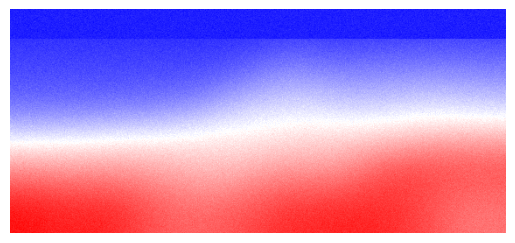

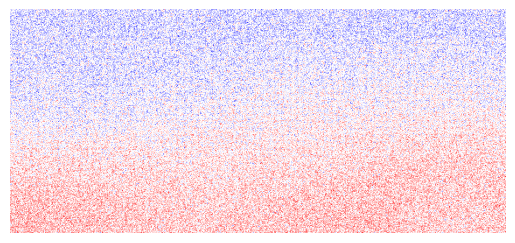

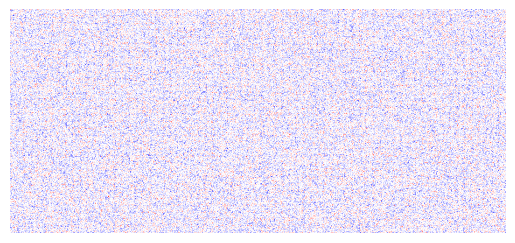

In [5]:
import scipy.io as sio
import torch.nn.functional as F
from utils.Diff_Utils import *
BT = 128
timesteps = 1000
model1 = model.clone()
model1 = model/model.max().abs()

gaussian_diffusion = GaussianDiffusion(timesteps=timesteps)
x_noisyall = []
for idx, t in enumerate([0, 99, timesteps-1]):
#for idx, t in enumerate([0, 99]):
    
    x_noisy = gaussian_diffusion.q_sample(model1.to(device), t=torch.tensor([t]).to(device))
    plt.figure()
    plt.imshow(x_noisy.detach().cpu(),cmap="bwr")
    plt.axis("off")


In [6]:
from torchsummary import summary
from Model.Module22_Diff_31 import *
import  torch


#Learning Schedule
def lr_lambda(epoch):
    return 10
def lr_lambda1(epoch):
    return 1/2

sim_lr = 1e-4
# define model and diffusion
device = "cuda" if torch.cuda.is_available() else "cpu"
netD = UNetModel(
    in_channels=1,
    model_channels=64,
    out_channels=1,
    num_res_blocks=4,
    attention_resolutions=(8, 16),
    dropout=0,
    channel_mult=(1, 2, 2),
    conv_resample=True,
    num_heads=4
)

### init the hyper-parameters of netD ###
netD = netD.to(device)
timesteps = 1000
batch_size = 8
num_epochs = 1000
ema_decay = 0.999
gaussian_diffusion = GaussianDiffusion(timesteps=timesteps)

"""Compute number of parameters"""
s  = sum(np.prod(list(p.size())) for p in netD.parameters())
print ('Number of netD params: %d' % s)

#summary(netD,[(1,nt,num_receivers_per_shot),(1,nt,num_receivers_per_shot)])


############## Init  ################# 
SNR = 0.0
SSIM = 0.0
Loss = 0.0
ERROR = 0.0

pa = 'Model/netD_ema256_MorePatches'
netD.load_state_dict(torch.load(pa, weights_only=True))



Number of netD params: 9941761


/home/sadalyom/.conda/envs/DAS_Denoising_Torch/lib/python3.8/site-packages/torch/_utils.py:831: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


<All keys matched successfully>

## DIIP-FWI

/home/sadalyom/.conda/envs/DAS_Denoising_Torch/lib/python3.8/site-packages/torch/nn/modules/conv.py:456: UserWarning: Applied workaround for CuDNN issue, install nvrtc.so (Triggered internally at /opt/conda/conda-bld/pytorch_1699449185072/work/aten/src/ATen/native/cudnn/Conv_v8.cpp:80.)
  return F.conv2d(input, weight, bias, self.stride,


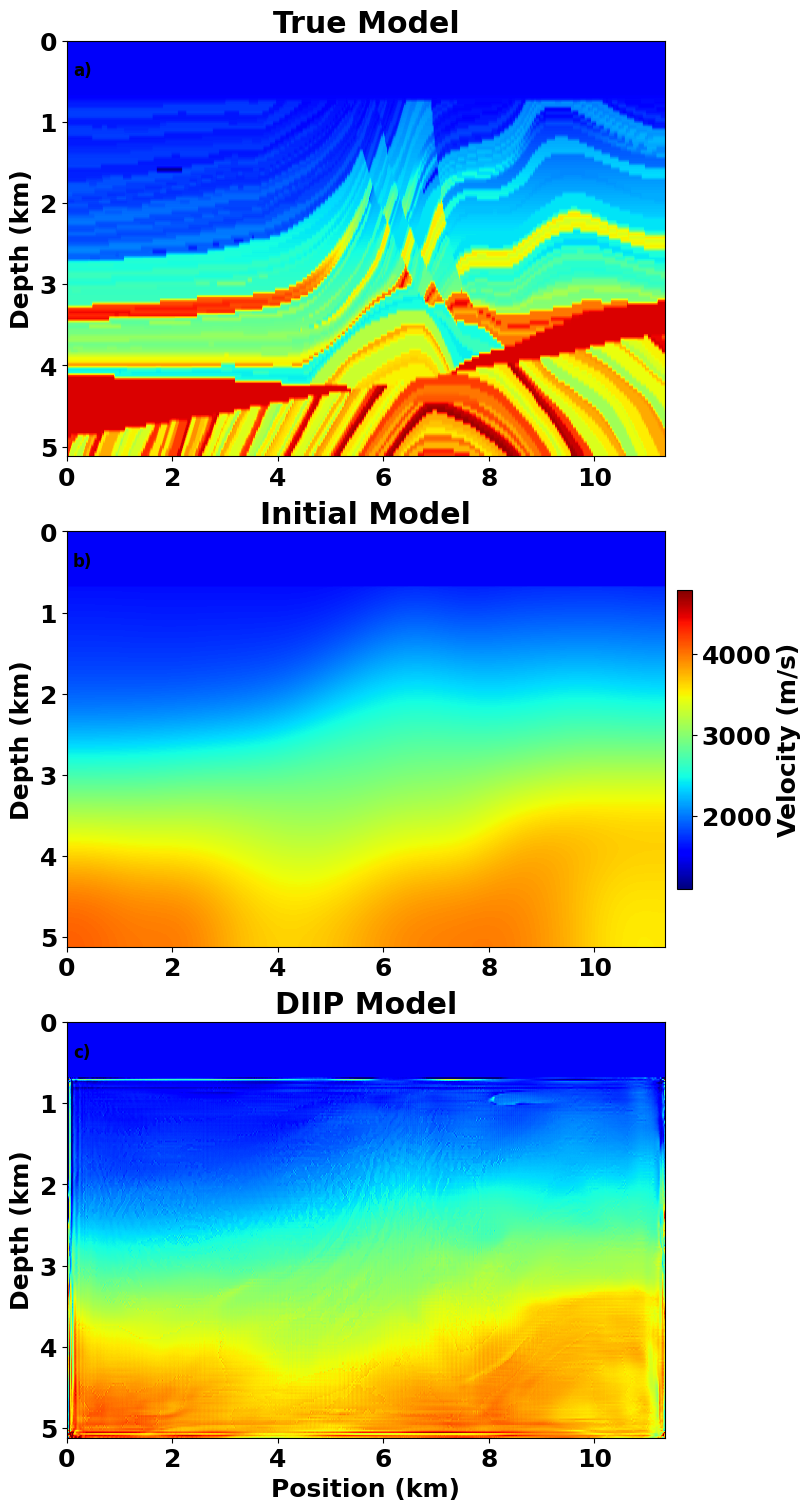

Epoch:    1 | t_int: 100 | K_inv:  3 | K_ddim:  3 | Loss: 1.15e-02 | lr_delta: 1.00e-02 | SNR: 16.770 | SSIM: 0.2016
Epoch:    2 | t_int: 100 | K_inv:  3 | K_ddim:  3 | Loss: 1.07e-02 | lr_delta: 1.00e-02 | SNR: 16.754 | SSIM: 0.1919
Epoch:    3 | t_int: 100 | K_inv:  3 | K_ddim:  3 | Loss: 9.92e-03 | lr_delta: 1.00e-02 | SNR: 16.746 | SSIM: 0.1893
Epoch:    4 | t_int: 100 | K_inv:  3 | K_ddim:  3 | Loss: 9.03e-03 | lr_delta: 1.00e-02 | SNR: 16.697 | SSIM: 0.1849
Epoch:    5 | t_int:  99 | K_inv:  3 | K_ddim:  3 | Loss: 8.73e-03 | lr_delta: 1.00e-02 | SNR: 16.636 | SSIM: 0.1827
Epoch:    6 | t_int:  99 | K_inv:  3 | K_ddim:  3 | Loss: 8.64e-03 | lr_delta: 1.00e-02 | SNR: 16.623 | SSIM: 0.1836
Epoch:    7 | t_int:  99 | K_inv:  3 | K_ddim:  3 | Loss: 7.95e-03 | lr_delta: 1.00e-02 | SNR: 16.554 | SSIM: 0.1839
Epoch:    8 | t_int:  98 | K_inv:  3 | K_ddim:  3 | Loss: 7.50e-03 | lr_delta: 1.00e-02 | SNR: 16.533 | SSIM: 0.1871
Epoch:    9 | t_int:  97 | K_inv:  3 | K_ddim:  3 | Loss: 7.47e-

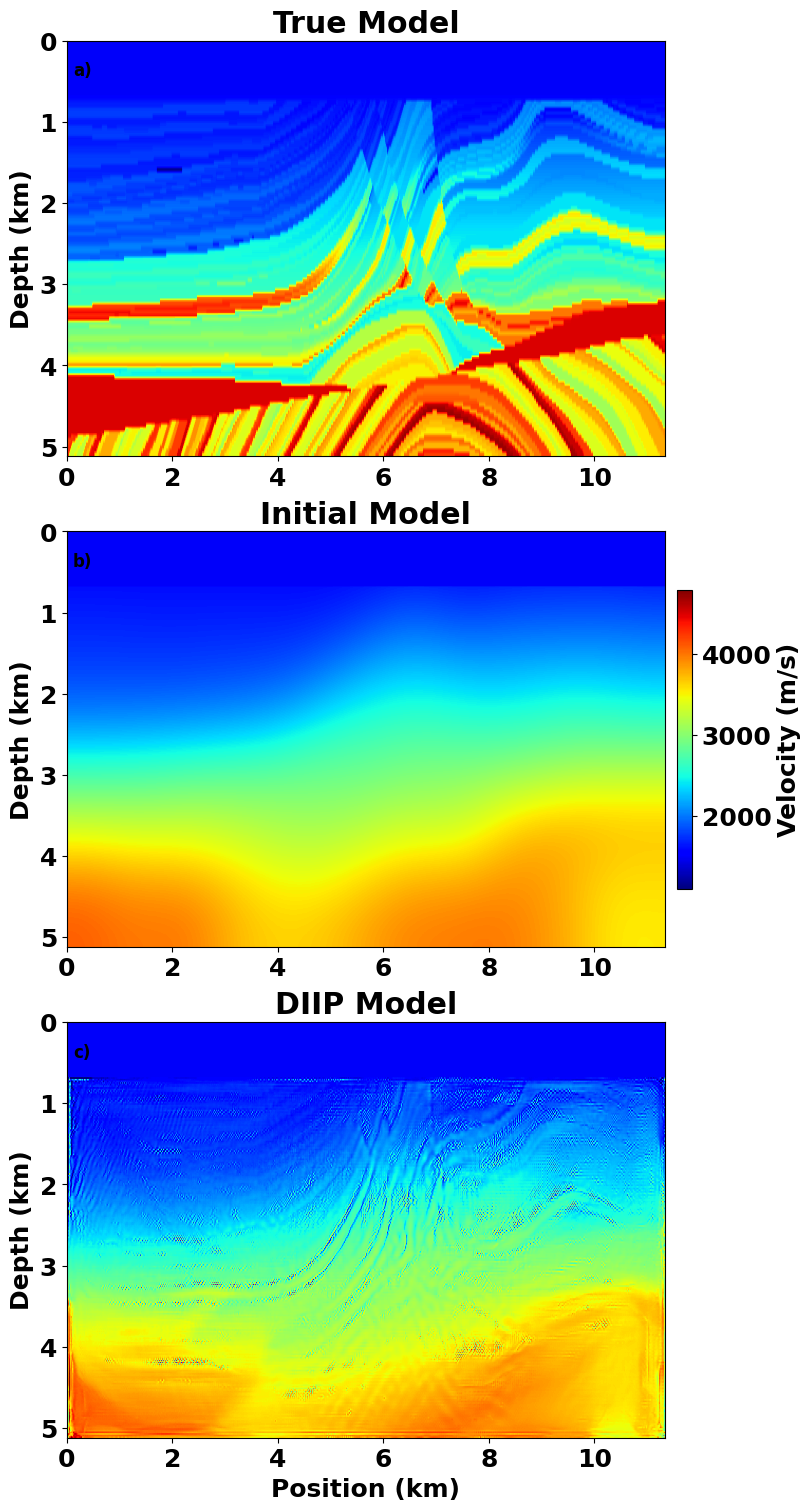

Epoch:   25 | t_int:  76 | K_inv:  3 | K_ddim:  3 | Loss: 5.99e-03 | lr_delta: 1.00e-02 | SNR: 16.535 | SSIM: 0.2074
Epoch:   26 | t_int:  74 | K_inv:  3 | K_ddim:  3 | Loss: 6.04e-03 | lr_delta: 1.00e-02 | SNR: 16.537 | SSIM: 0.2064
Epoch:   27 | t_int:  72 | K_inv:  3 | K_ddim:  3 | Loss: 6.09e-03 | lr_delta: 1.00e-02 | SNR: 16.536 | SSIM: 0.2084
Epoch:   28 | t_int:  70 | K_inv:  3 | K_ddim:  3 | Loss: 6.59e-03 | lr_delta: 1.00e-02 | SNR: 16.549 | SSIM: 0.2095
Epoch:   29 | t_int:  68 | K_inv:  3 | K_ddim:  3 | Loss: 6.00e-03 | lr_delta: 1.00e-02 | SNR: 16.562 | SSIM: 0.2123
Epoch:   30 | t_int:  65 | K_inv:  3 | K_ddim:  3 | Loss: 6.49e-03 | lr_delta: 1.00e-02 | SNR: 16.590 | SSIM: 0.2133
Epoch:   31 | t_int:  63 | K_inv:  3 | K_ddim:  3 | Loss: 6.10e-03 | lr_delta: 1.00e-02 | SNR: 16.577 | SSIM: 0.2109
Epoch:   32 | t_int:  60 | K_inv:  3 | K_ddim:  3 | Loss: 6.21e-03 | lr_delta: 1.00e-02 | SNR: 16.617 | SSIM: 0.2166
Epoch:   33 | t_int:  58 | K_inv:  3 | K_ddim:  3 | Loss: 5.99e-

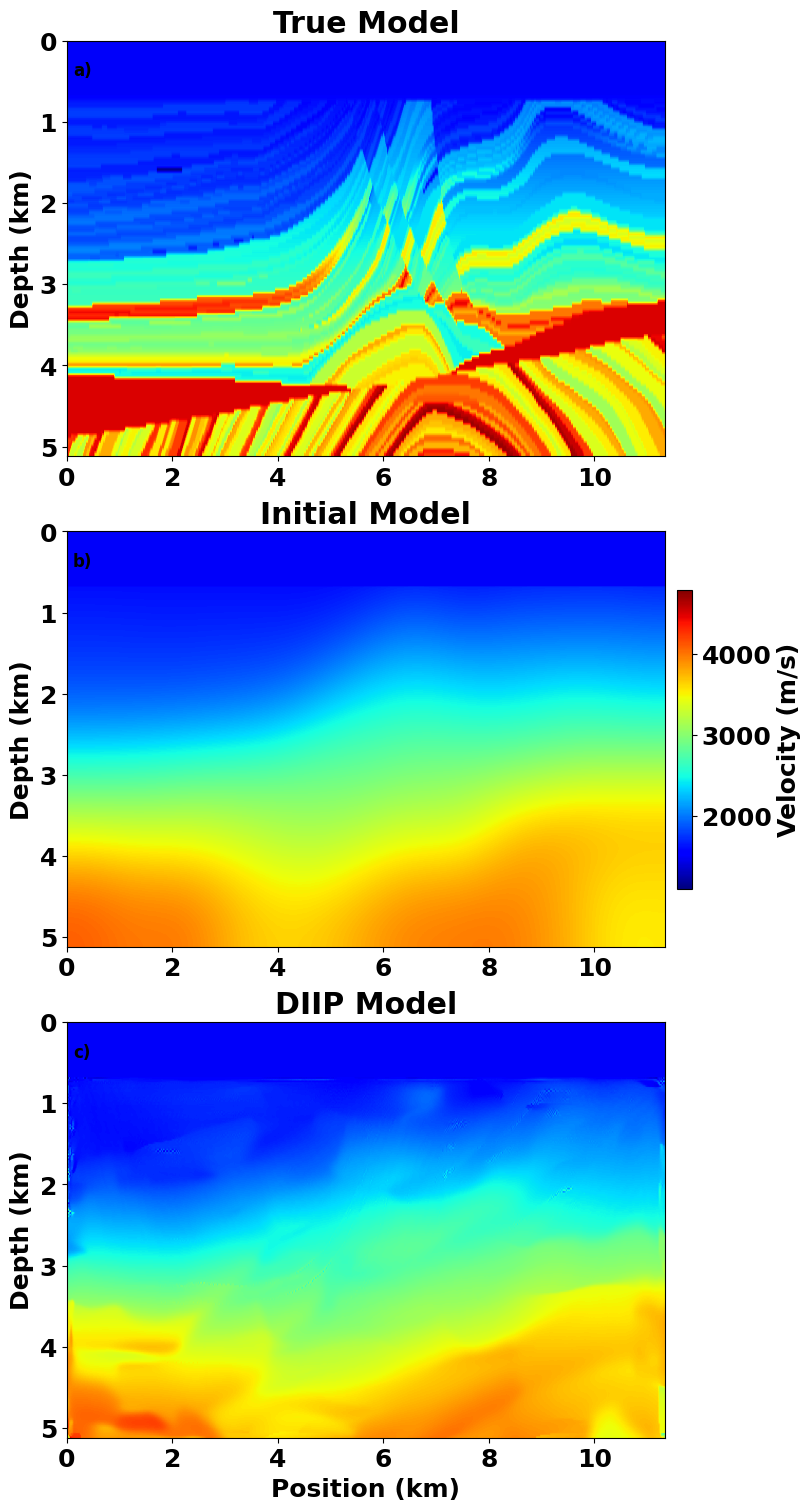

Epoch:   50 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 8.34e-03 | lr_delta: 1.00e-02 | SNR: 16.906 | SSIM: 0.2530
Epoch:   51 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 7.79e-03 | lr_delta: 1.00e-02 | SNR: 16.946 | SSIM: 0.2647
Epoch:   52 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 7.26e-03 | lr_delta: 1.00e-02 | SNR: 16.971 | SSIM: 0.2704
Epoch:   53 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 6.71e-03 | lr_delta: 1.00e-02 | SNR: 16.991 | SSIM: 0.2797
Epoch:   54 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 6.17e-03 | lr_delta: 1.00e-02 | SNR: 17.011 | SSIM: 0.2896
Epoch:   55 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 6.34e-03 | lr_delta: 1.00e-02 | SNR: 17.006 | SSIM: 0.2965
Epoch:   56 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 5.94e-03 | lr_delta: 1.00e-02 | SNR: 17.025 | SSIM: 0.3029
Epoch:   57 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 5.56e-03 | lr_delta: 1.00e-02 | SNR: 17.028 | SSIM: 0.3103
Epoch:   58 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 5.16e-

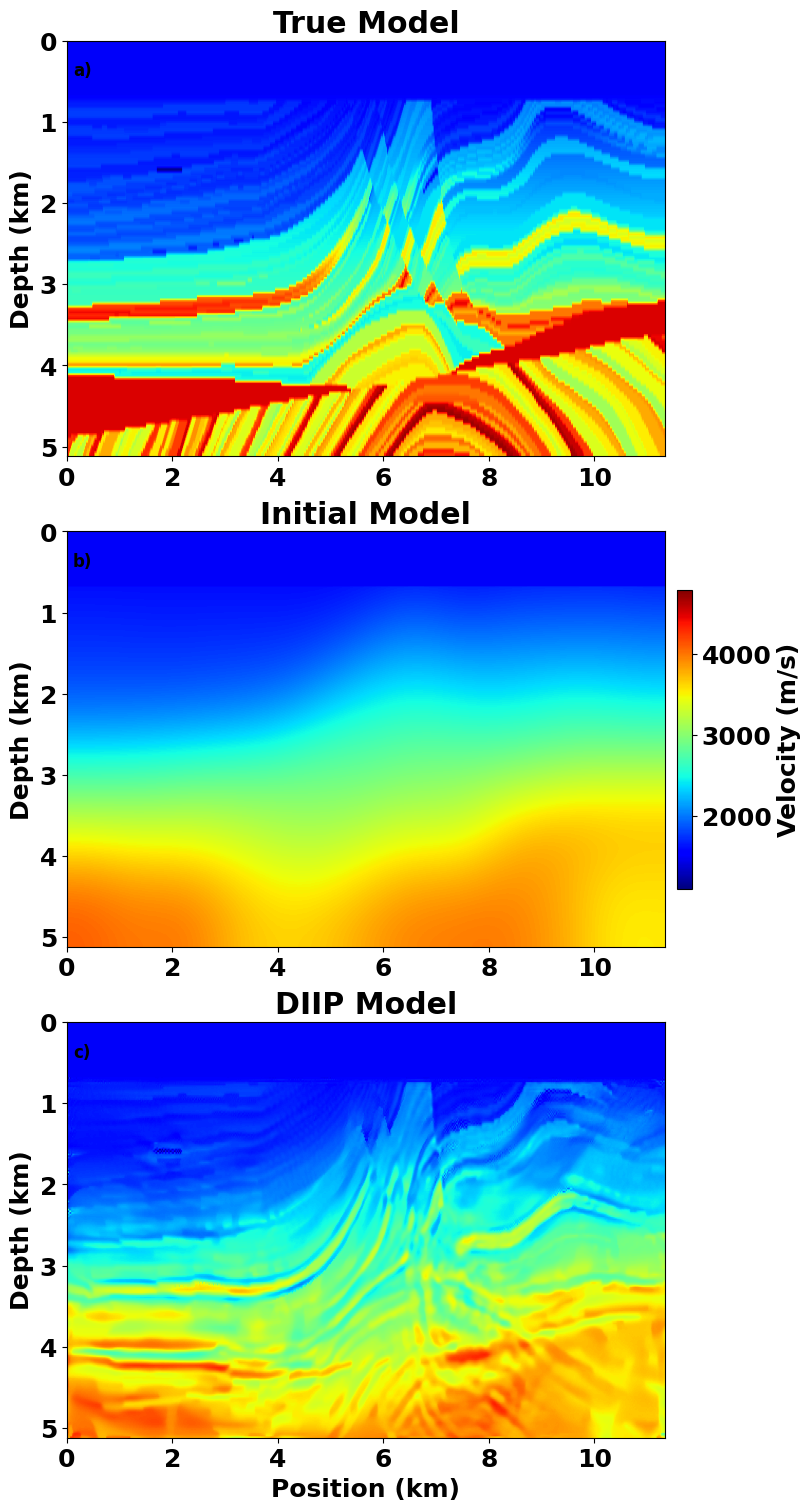

Epoch:   75 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 4.12e-03 | lr_delta: 1.00e-02 | SNR: 17.249 | SSIM: 0.3737
Epoch:   76 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.81e-03 | lr_delta: 1.00e-02 | SNR: 17.262 | SSIM: 0.3773
Epoch:   77 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.66e-03 | lr_delta: 1.00e-02 | SNR: 17.268 | SSIM: 0.3794
Epoch:   78 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.72e-03 | lr_delta: 1.00e-02 | SNR: 17.277 | SSIM: 0.3839
Epoch:   79 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.54e-03 | lr_delta: 1.00e-02 | SNR: 17.294 | SSIM: 0.3875
Epoch:   80 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.74e-03 | lr_delta: 1.00e-02 | SNR: 17.299 | SSIM: 0.3906
Epoch:   81 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.42e-03 | lr_delta: 1.00e-02 | SNR: 17.305 | SSIM: 0.3936
Epoch:   82 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.56e-03 | lr_delta: 1.00e-02 | SNR: 17.308 | SSIM: 0.3954
Epoch:   83 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 4.11e-

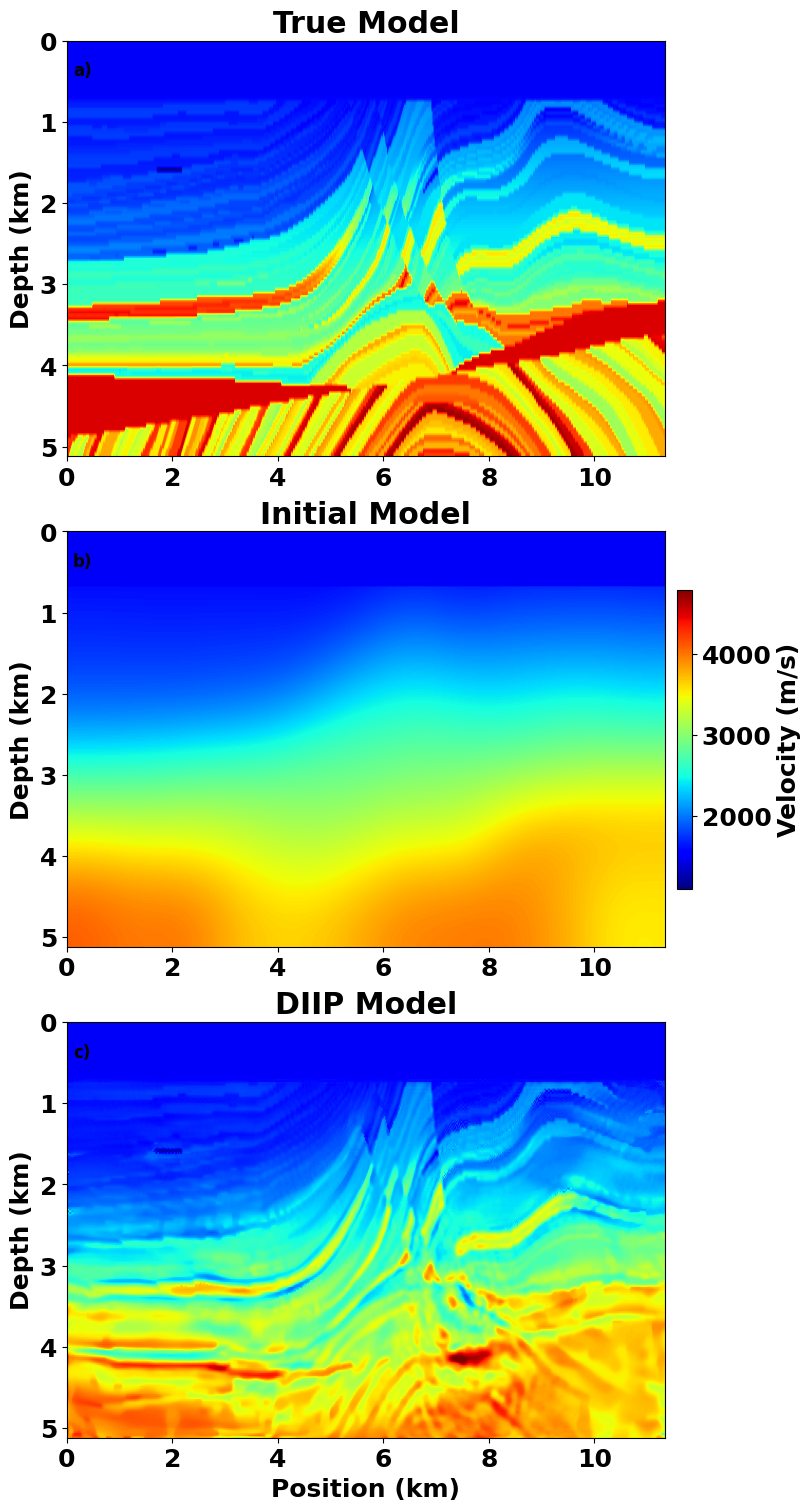

Epoch:  100 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.16e-03 | lr_delta: 1.00e-02 | SNR: 17.446 | SSIM: 0.4349
Epoch:  101 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.28e-03 | lr_delta: 1.00e-02 | SNR: 17.460 | SSIM: 0.4368
Epoch:  102 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.90e-03 | lr_delta: 1.00e-02 | SNR: 17.463 | SSIM: 0.4388
Epoch:  103 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 2.96e-03 | lr_delta: 1.00e-02 | SNR: 17.481 | SSIM: 0.4417
Epoch:  104 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.22e-03 | lr_delta: 1.00e-02 | SNR: 17.491 | SSIM: 0.4420
Epoch:  105 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.21e-03 | lr_delta: 1.00e-02 | SNR: 17.496 | SSIM: 0.4440
Epoch:  106 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.09e-03 | lr_delta: 1.00e-02 | SNR: 17.501 | SSIM: 0.4456
Epoch:  107 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.60e-03 | lr_delta: 1.00e-02 | SNR: 17.514 | SSIM: 0.4469
Epoch:  108 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.30e-

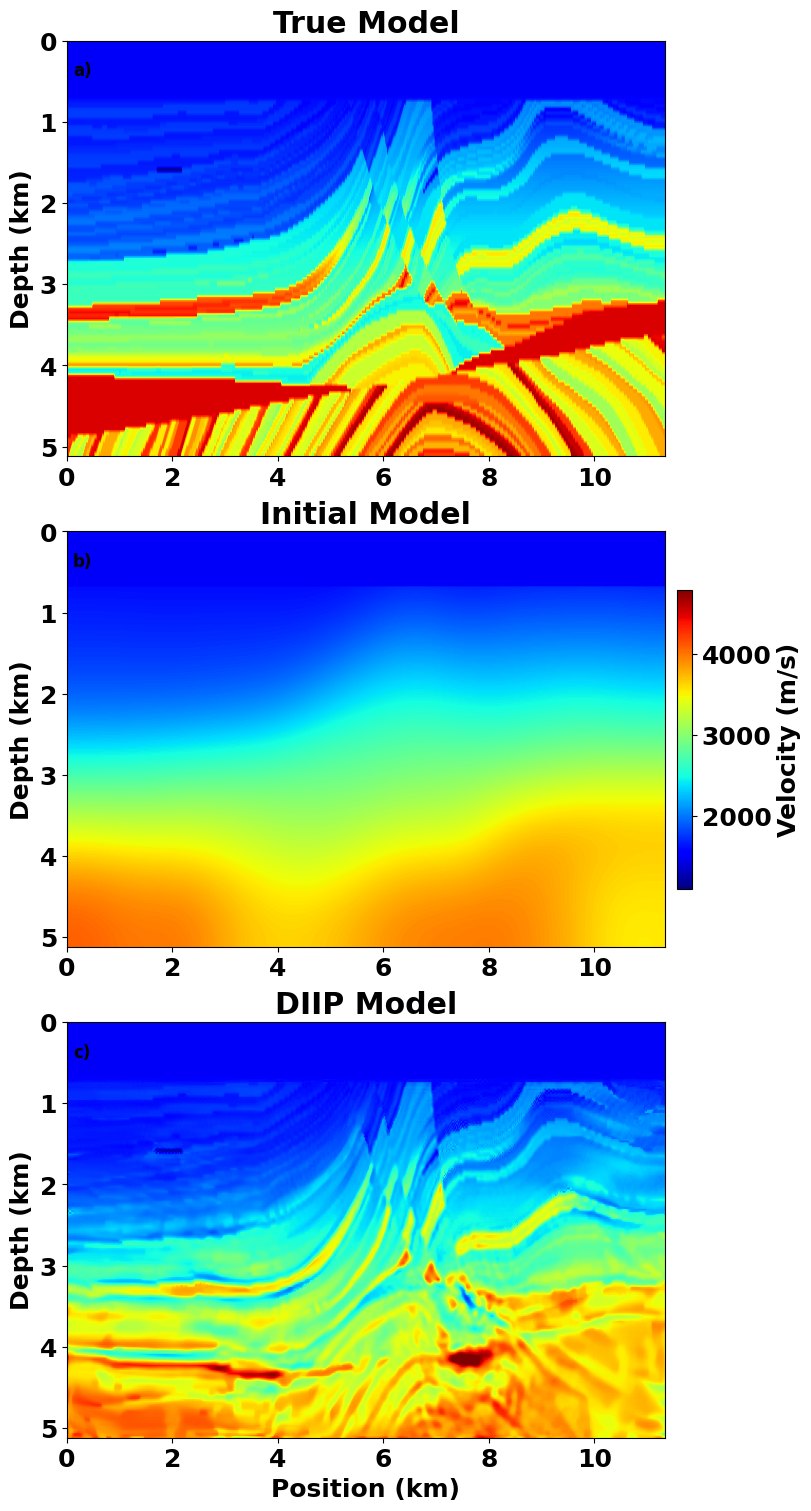

Epoch:  125 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.06e-03 | lr_delta: 1.00e-02 | SNR: 17.630 | SSIM: 0.4656
Epoch:  126 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.10e-03 | lr_delta: 1.00e-02 | SNR: 17.622 | SSIM: 0.4657
Epoch:  127 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.01e-03 | lr_delta: 1.00e-02 | SNR: 17.648 | SSIM: 0.4668
Epoch:  128 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 2.82e-03 | lr_delta: 1.00e-02 | SNR: 17.649 | SSIM: 0.4682
Epoch:  129 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.28e-03 | lr_delta: 1.00e-02 | SNR: 17.659 | SSIM: 0.4701
Epoch:  130 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.09e-03 | lr_delta: 1.00e-02 | SNR: 17.659 | SSIM: 0.4708
Epoch:  131 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 2.75e-03 | lr_delta: 1.00e-02 | SNR: 17.665 | SSIM: 0.4715
Epoch:  132 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 2.83e-03 | lr_delta: 1.00e-02 | SNR: 17.675 | SSIM: 0.4730
Epoch:  133 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.55e-

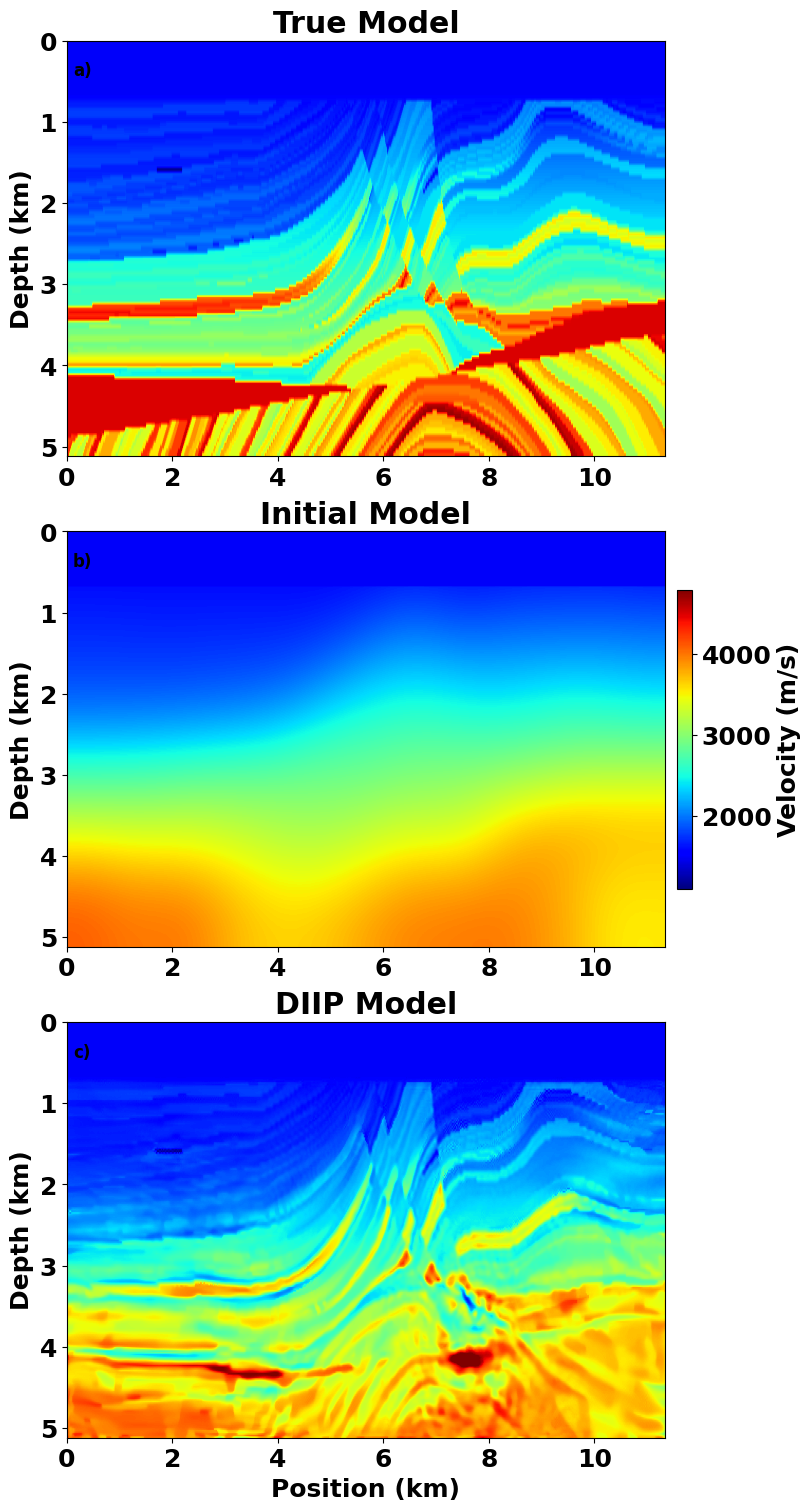

Epoch:  150 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.10e-03 | lr_delta: 1.00e-02 | SNR: 17.791 | SSIM: 0.4853
Epoch:  151 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.06e-03 | lr_delta: 1.00e-02 | SNR: 17.797 | SSIM: 0.4855
Epoch:  152 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 2.66e-03 | lr_delta: 1.00e-02 | SNR: 17.812 | SSIM: 0.4878
Epoch:  153 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 2.72e-03 | lr_delta: 1.00e-02 | SNR: 17.798 | SSIM: 0.4869
Epoch:  154 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 2.83e-03 | lr_delta: 1.00e-02 | SNR: 17.806 | SSIM: 0.4874
Epoch:  155 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.25e-03 | lr_delta: 1.00e-02 | SNR: 17.824 | SSIM: 0.4876
Epoch:  156 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.13e-03 | lr_delta: 1.00e-02 | SNR: 17.831 | SSIM: 0.4887
Epoch:  157 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.00e-03 | lr_delta: 1.00e-02 | SNR: 17.842 | SSIM: 0.4903
Epoch:  158 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.12e-

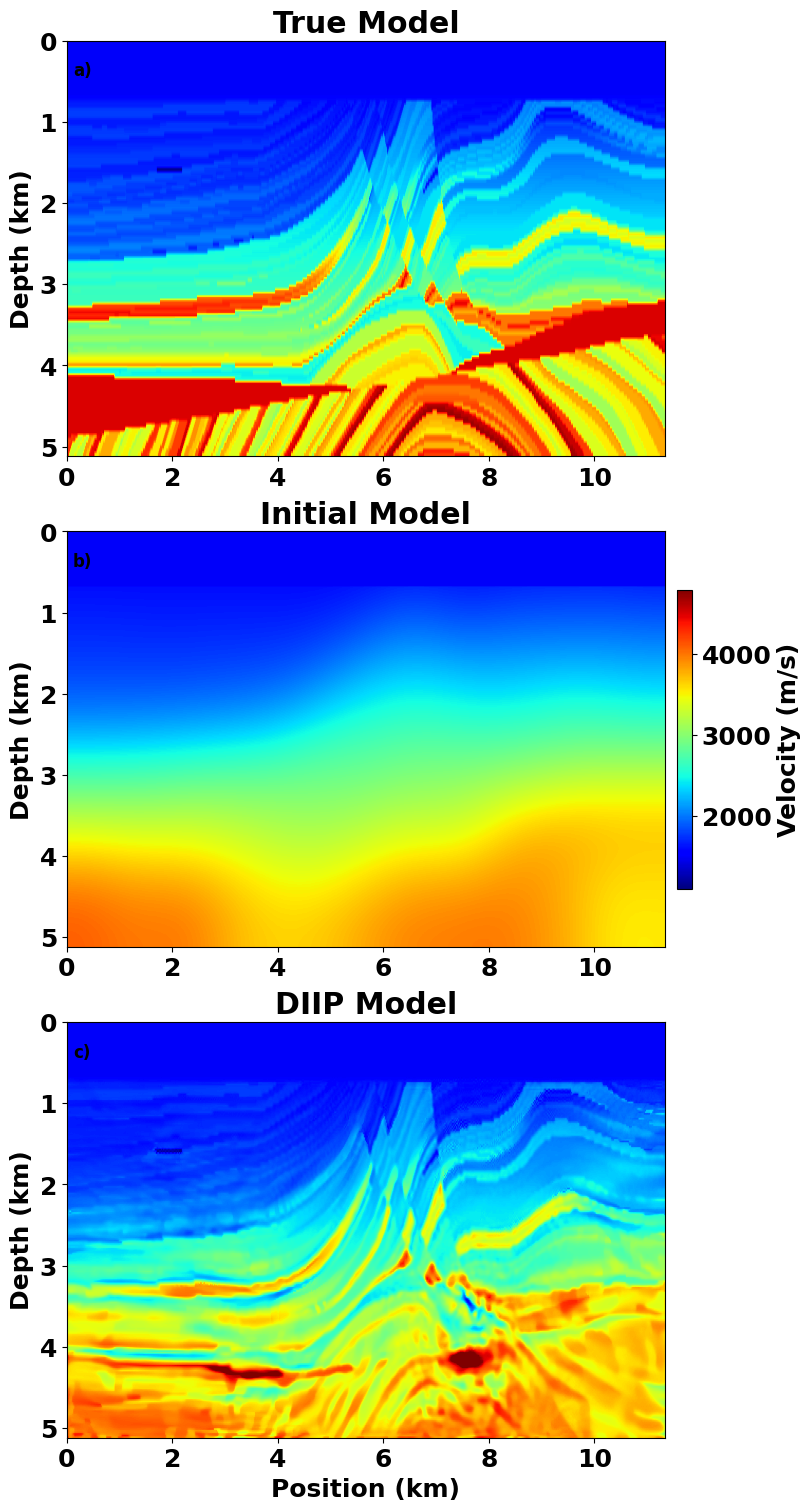

Epoch:  175 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 2.68e-03 | lr_delta: 1.00e-02 | SNR: 17.927 | SSIM: 0.5005
Epoch:  176 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 2.42e-03 | lr_delta: 1.00e-02 | SNR: 17.944 | SSIM: 0.5018
Epoch:  177 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 2.62e-03 | lr_delta: 1.00e-02 | SNR: 17.934 | SSIM: 0.5014
Epoch:  178 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 2.79e-03 | lr_delta: 1.00e-02 | SNR: 17.931 | SSIM: 0.5020
Epoch:  179 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 2.75e-03 | lr_delta: 1.00e-02 | SNR: 17.942 | SSIM: 0.5023
Epoch:  180 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.24e-03 | lr_delta: 1.00e-02 | SNR: 17.940 | SSIM: 0.5031
Epoch:  181 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.01e-03 | lr_delta: 1.00e-02 | SNR: 17.951 | SSIM: 0.5035
Epoch:  182 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 2.72e-03 | lr_delta: 1.00e-02 | SNR: 17.958 | SSIM: 0.5025
Epoch:  183 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 2.32e-

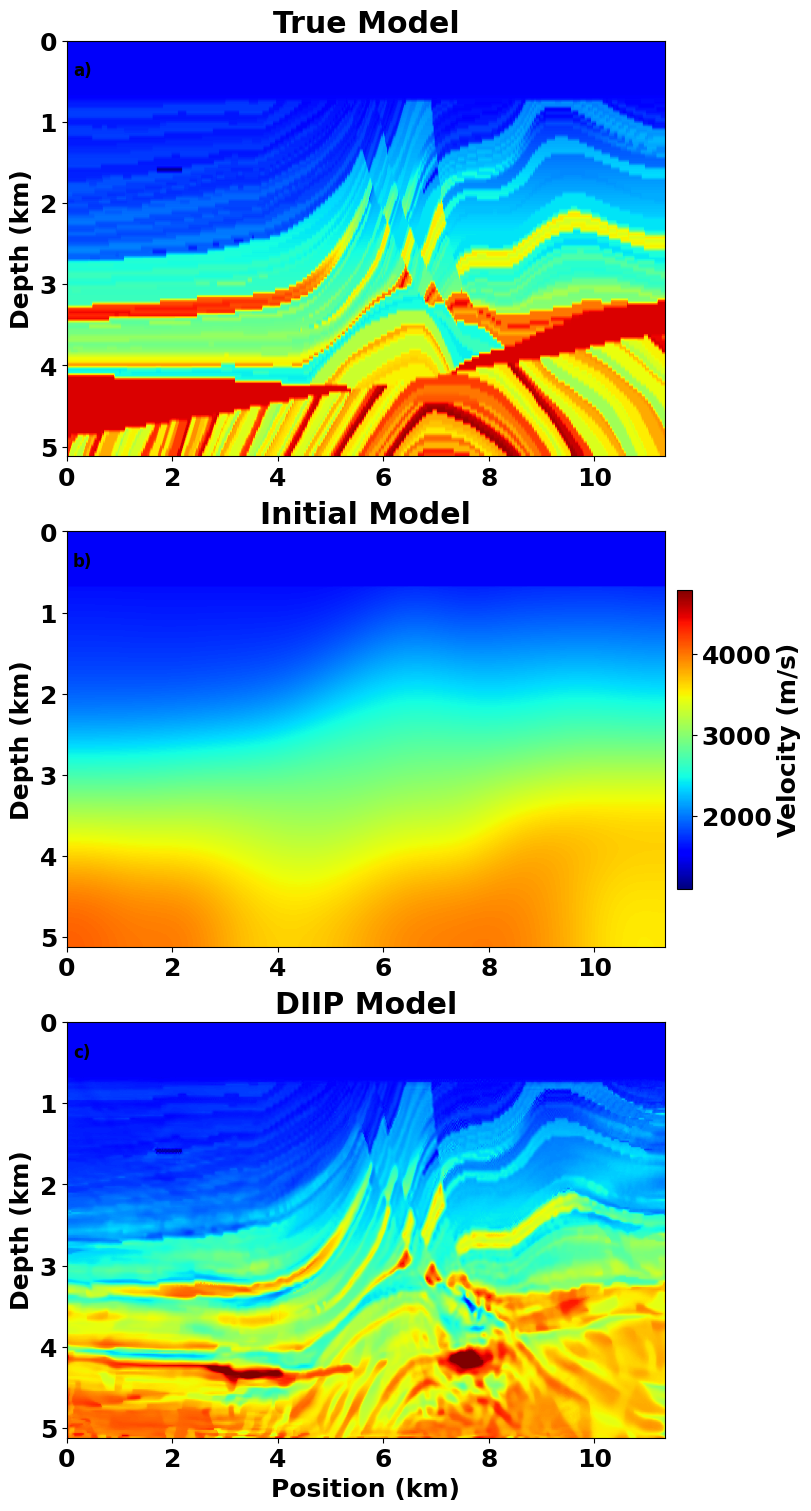

Epoch:  200 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 2.19e-03 | lr_delta: 1.00e-02 | SNR: 18.058 | SSIM: 0.5169
Done in 8.77 min


In [7]:
 
import time
import numpy as np
import torch
import torch.nn.functional as F


# ============================================================
# SETTINGS (tune)
# ============================================================
# DIIP / DDIM

vmin = 1100
vmax = 4800
w1, w2 = 256, 256
o1, o2 = w1 // 2, w2 // 2
nz = model_true.shape[0]
ny = model_true.shape[1]

t_start, t_end   = 100, 1              # schedule high->low
warm_epochs      = 50
power_t          = 2.0

K                = 3                    # reverse DDIM steps (expensive, in-graph)
Kf               = 3
eta_ddim         = 0                  # deterministic (DIIP / inversion)

patch_chunk      = 1                    # chunk patches to fit VRAM (1,2,4...)
use_checkpoint   = True                 # if your chunked function supports it
use_amp          = True
amp_dtype        = torch.float16

# delta optimization
lr_start, lr_end = 1e-2, 1e-2
power_lr         = 2.0
grad_clip        = 1

# forward modeling batching
shot_batch       = 4                    # try 4/8/16 (depends on DeepWave memory)

# optional restart of delta

# ============================================================
# Freeze diffusion netD
# ============================================================
netD.eval()
for p in netD.parameters():
    p.requires_grad_(False)

scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

# ============================================================


# ============================================================
# Prepare base model (velocity)
# ============================================================
v_base = model.clone().detach().to(device)     # (H,W)
H, W = v_base.shape
model_true2d = model_true.view(nz, ny)

# ============================================================
# Build initial patches from base
# ============================================================
def vel_to_patches(v):
    v_n = normalize_vel(v,vmin,vmax)  # [-1,1]
    return patch_torch(v_n, w1, w2, o1, o2).reshape(-1, 1, w1, w2)

def patches_to_vel(x0_hat, H, W):
    v_new_n = patch_inv_torch_gaussian(
        x0_hat.reshape(-1, w1 * w2),
        H, W, w1, w2, o1, o2,
        sigma1=w1/6, sigma2=w2/6
    )
    return denormalize_vel(v_new_n,vmin,vmax)

# ============================================================
# Init inversion latent + delta
# ============================================================
v0_p = vel_to_patches(v_base)             # (B,1,w1,w2)
B = v0_p.shape[0]

# initial schedule values
t_int0 = t_start

# invert once (no-grad)
x_t_inv, ts = gaussian_diffusion.ddim_invert_x0_to_xt(
    model=netD,
    x0=v0_p,
    t_start=t_int0,
    K=Kf,
    clip_denoised=False,
    use_amp=False
)
# delta (trainable)
delta = torch.zeros_like(x_t_inv, device=device, requires_grad=True)

optim_delta = torch.optim.Adam([delta], lr=lr_start, betas=(0.5, 0.9), eps=1e-12)

# ============================================================
# Main FWI loop
# ============================================================
t0_global = time.time()

for epoch in range(fwi_num_epochs):

    # ---------------------------
    # schedule t_int and lr
    # ---------------------------
    if epoch < warm_epochs:
        p = epoch / max(1, warm_epochs - 1)
        t_int = int(round(t_start + (t_end - t_start) * (p ** power_t)))
        lr_now = float(lr_start + (lr_end - lr_start) * (p ** power_lr))
    else:
        t_int, lr_now = t_end, float(lr_end)

    for pg in optim_delta.param_groups:
        pg["lr"] = lr_now

    # ---------------------------
    # shots subset
    # ---------------------------
    indx = np.random.permutation(fwi_batch)
    ind = indx[: fwi_batch // 2]
    nshots = len(ind)

    epoch_loss = 0.0
    
    #if epoch<=warm_epochs:
        
    # invert once (no-grad)
    #x_t_inv = ddim_invert_x0_to_xt(gaussian_diffusion, netD, v0_p, t_start=t_int, K=K_inv)
    x_t_inv, ts = gaussian_diffusion.ddim_invert_x0_to_xt(
        model=netD,
        x0=v0_p,
        t_start=t_int,
        K=Kf,
        clip_denoised=False,
        use_amp=False
    )
    # ---------------------------
    # shot mini-batches
    # ---------------------------
    for s0 in range(0, nshots, shot_batch):
        s1 = min(s0 + shot_batch, nshots)
        shot_ids = ind[s0:s1]

        optim_delta.zero_grad(set_to_none=True)

        # ===========================
        # (A) DIIP mapping: latent -> x0_hat -> velocity
        # ===========================
        if use_amp:
            ctx = torch.cuda.amp.autocast(dtype=amp_dtype)
        else:
            from contextlib import nullcontext
            ctx = nullcontext()

        with ctx:
            # take the inverted latent at the CURRENT t_int
            # (simple approach: re-noise x0 to current t_int using the deterministic latent x_t_inv)
            # We keep x_t_inv computed at t_start, but we can still run reverse from t_int
            # by just setting the starting x_t = x_t_inv + delta and calling reverse with t_start=t_int.
            #
            # If you want strict consistency: you can recompute x_t_inv each epoch for the current t_int (costly).
            #
            x_t = x_t_inv + delta

            # reverse DDIM (chunked, differentiable) -> x0_hat
            x0_hat = gaussian_diffusion.ddim_x0_from_xt_with_ts_chunked(
                model=netD,
                x_t=x_t,
                ts=ts,
                eta=0.0,
                clip_denoised=False,
                patch_chunk=patch_chunk,
                use_checkpoint=False,   # for test
                use_amp=False
            )

            # unpatch to velocity
            v_new = patches_to_vel(x0_hat, H, W)

            # smooth below water only (optional)
            #v_s = smooth_velocity_gaussian(v_new, kernel_size=5, sigma=1.0)

            # keep water untouched
            v_new = v_new.clone()
            v_new[:34, :] = 1500.0


            # ===========================
            # (B) Forward modeling loss (SHOT MINI-BATCH)
            # ===========================
            batch_src_amps = source[shot_ids].to(device)
            batch_rcv_true = rcv_amps_true[shot_ids].to(device)
            batch_x_s = x_s[shot_ids].to(device)
            batch_x_r = x_r[shot_ids].to(device)

            batch_rcv_pred = scalar(
                v_new, dx, dt,
                source_amplitudes=batch_src_amps,
                source_locations=batch_x_s,
                receiver_locations=batch_x_r,
                accuracy=8,
                pml_width=pml_width
            )[-1]

            d_real = batch_rcv_true / (torch.norm(batch_rcv_true, p=2) + 1e-12)
            d_fake = batch_rcv_pred / (torch.norm(batch_rcv_pred, p=2) + 1e-12)

            loss = F.pairwise_distance(d_fake, d_real, keepdim=True).mean()

        epoch_loss += float(loss.item()) * (s1 - s0)

        # ===========================
        # (C) Backprop + update delta
        # ===========================
        if use_amp:
            scaler.scale(loss).backward()
            scaler.unscale_(optim_delta)
            torch.nn.utils.clip_grad_norm_([delta], grad_clip)
            scaler.step(optim_delta)
            scaler.update()
        else:
            loss.backward()
            torch.nn.utils.clip_grad_norm_([delta], grad_clip)
            optim_delta.step()

    # normalize epoch loss
    epoch_loss /= max(1, nshots)

    # metrics
    snr = ComputeSNR(v_new.detach().cpu().numpy(), model_true2d.detach().cpu().numpy())
    ssim = ComputeSSIM(v_new.detach().cpu().numpy(), model_true2d.detach().cpu().numpy())

    if (epoch + 1) % 25 == 0 or epoch == 0:
        fig, axes = plot_velocity_models(
            model_true=model_true2d,
            model_init=model_init,
            model_result=v_new,
            dx=dx,
            vmin=vmin,
            vmax=vmax,
            figsize = (8,15),
        )

    print(
        f"Epoch: {epoch+1:4d} | t_int: {t_int:3d} | K_inv: {K:2d} | K_ddim: {K:2d} | "
        f"Loss: {epoch_loss:.2e} | lr_delta: {lr_now:.2e} | "
        f"SNR: {snr:.3f} | SSIM: {float(ssim):.4f}"
    )

t1_global = time.time()
print(f"Done in {(t1_global - t0_global)/60:.2f} min")
spio.savemat(fwi_result + "DIIP_Recon.mat", {"rec": v_new.detach().cpu().numpy()})

## Plotting the Reconstructed Velocity Model

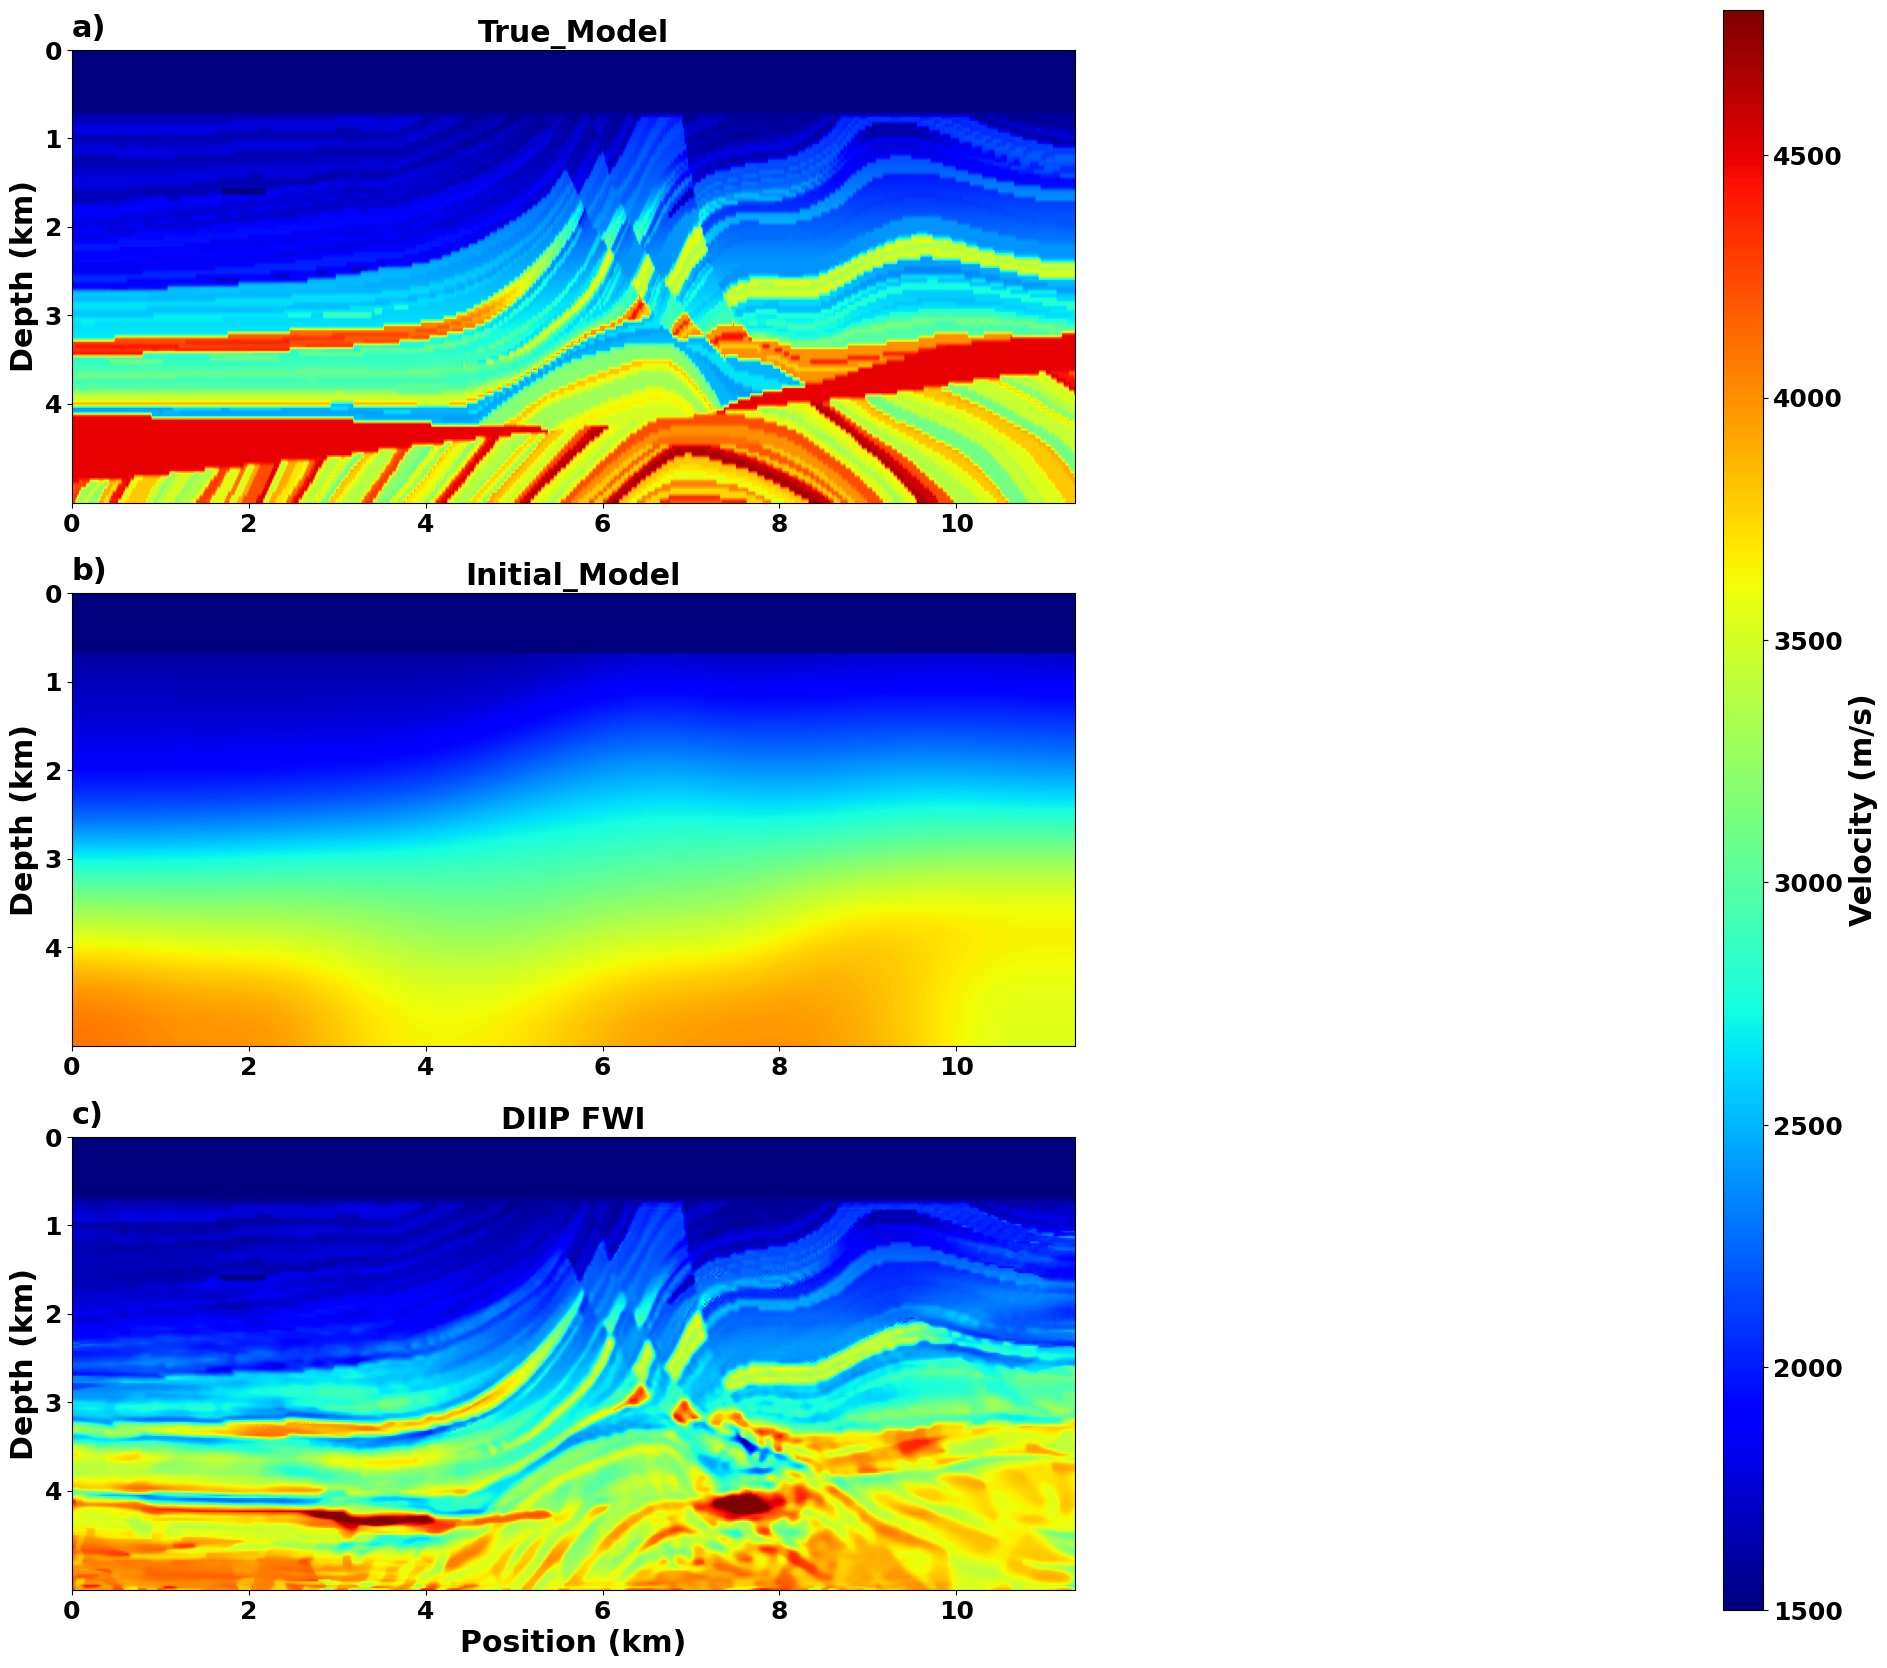

The reconstructed velocity model has SNR: 18.057971036267364 dB and SSIM: 0.5168604


In [8]:
f, ax = plt.subplots(3,1,figsize=(40, 20))
plt.rc('font', **font)

# True Model
modeltrue = model1
im = ax[0].imshow(model_true.detach().cpu().numpy(), cmap='jet', vmin=box_min, vmax=box_max, 
                extent=[0, modeltrue.shape[1] * dx / 1000, modeltrue.shape[0] * dx / 1000, 0])

#ax[0].set_xlabel('Position (km)',fontsize='large', fontweight='bold')
ax[0].set_ylabel('Depth (km)',fontsize='large', fontweight='bold')
ax[0].set_title('True_Model',fontsize='large', fontweight='bold')
ax[0].text(0, -0.15, 'a)', fontsize = 22) 
ax[0].xaxis.set_major_locator(MaxNLocator(integer=True))
ax[0].set_yticks(np.arange(y.min(), y.max(), 1)) 

# Initial Model
init_V = model_init.detach().cpu().numpy()
im = ax[1].imshow(init_V, cmap='jet', vmin=box_min, vmax=box_max, 
                extent=[0, init_V.shape[1] * dx / 1000, init_V.shape[0] * dx / 1000, 0])
#ax[1].set_xlabel('Position (km)',fontsize='large', fontweight='bold')
ax[1].set_ylabel('Depth (km)',fontsize='large', fontweight='bold')
ax[1].set_title('Initial_Model',fontsize='large', fontweight='bold')
ax[1].text(0, -0.15, 'b)', fontsize = 22) 
ax[1].xaxis.set_major_locator(MaxNLocator(integer=True))
ax[1].set_yticks(np.arange(y.min(), y.max(), 1)) 

# Siamese Model
Siamese_Vel = scipy.io.loadmat(fwi_result + 'DIIP_Recon.mat')
Siamese_Vel = Siamese_Vel['rec']
im = ax[2].imshow(Siamese_Vel, cmap='jet', vmin=box_min, vmax=box_max, 
                extent=[0, v_new.shape[1] * dx / 1000, v_new.shape[0] * dx / 1000, 0])
ax[2].set_xlabel('Position (km)',fontsize='large', fontweight='bold')
ax[2].set_ylabel('Depth (km)',fontsize='large', fontweight='bold')
ax[2].set_title('DIIP FWI',fontsize='large', fontweight='bold')
ax[2].text(0, -0.15, 'c)', fontsize = 22) 
ax[2].xaxis.set_major_locator(MaxNLocator(integer=True))
ax[2].set_yticks(np.arange(y.min(), y.max(), 1)) 


cbar_ax = f.add_axes([0.8, 0.1, 0.01, 0.8])
f.colorbar(im, fraction=0.005, pad=0.04,cax=cbar_ax)
cbar_ax.set_ylabel('Velocity (m/s)',fontsize='large', fontweight='bold')

plt.show()

snr = ComputeSNR(Siamese_Vel,  
          model_true.detach().cpu().numpy())

ssim = ComputeSSIM(Siamese_Vel, \
          model_true.detach().cpu().numpy())

print('The reconstructed velocity model has SNR:', str(snr), 'dB', 'and SSIM:',str(ssim.cpu().detach().cpu().numpy()))

## Plotting Velocities Profiles

@Position =  1.6 km, RMSE =  0.3590926636923514 km/s
@Position =  4.8 km, RMSE =  0.21175055634437895 km/s
@Position =  9.6 km, RMSE =  0.38212851317902413 km/s


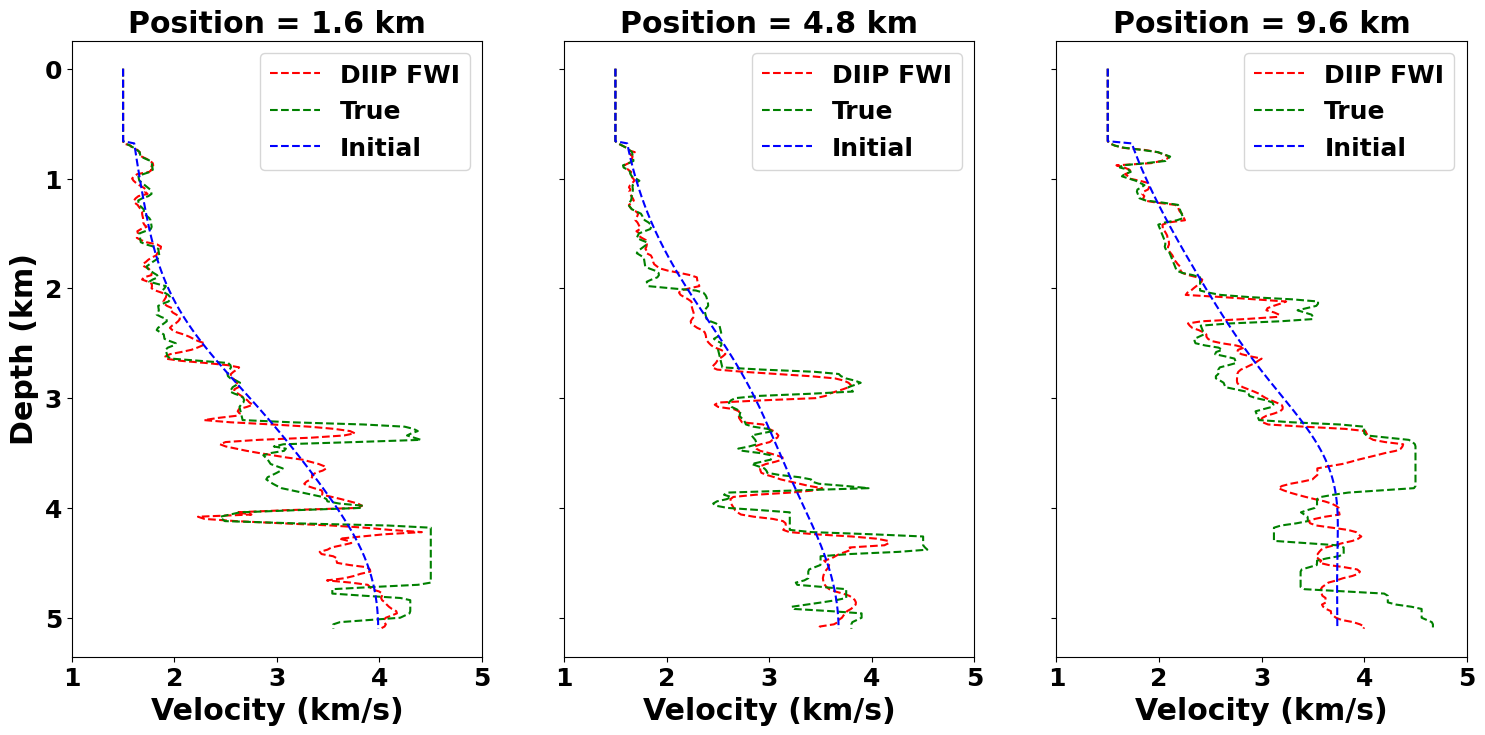

In [9]:
from math import sqrt

# position 1
k = 80

xy = np.arange(0,Siamese_Vel.shape[0] * dx / 1000, len(Siamese_Vel[:,k])/Siamese_Vel.shape[0] * dx / 1000)
f, ax = plt.subplots(figsize=(18, 8), ncols=3,nrows=1)
xx = np.arange(0,5)
ax[0].plot(Siamese_Vel[:,k]/1000,xy,'r--',label='DIIP FWI')
ax[0].plot(model_true.detach().cpu().numpy()[:,k]/1000,xy,'g--',label='True')
ax[0].plot(init_V[:,k]/1000,xy,'b--',label='Initial')
ax[0].set_ylabel('Depth (km)',fontsize='large', fontweight='bold')
ax[0].set_xlabel('Velocity (km/s)',fontsize='large', fontweight='bold')
ax[0].set_xlim([1,5])
ax[0].legend(loc='upper right')
ax[0].set_title( 'Position = ' + str(k * dx / 1000) +' km',fontsize='large', fontweight='bold')
ax[0].invert_yaxis()
rms = sqrt(np.mean(((model_true.detach().cpu().numpy()[:,k]-Siamese_Vel[:,k])/1000)**2))
print('@Position = ', str(k * dx / 1000), 'km, RMSE = ',str(rms), 'km/s')

# position 2
k = 240
xy = np.arange(0,Siamese_Vel.shape[0] * dx / 1000, len(Siamese_Vel[:,k])/Siamese_Vel.shape[0] * dx / 1000)
xx = np.arange(0,4)
ax[1].plot(Siamese_Vel[:,k]/1000,xy,'r--',label='DIIP FWI')
ax[1].plot(model_true.detach().cpu().numpy()[:,k]/1000,xy,'g--',label='True')
ax[1].plot(init_V[:,k]/1000,xy,'b--',label='Initial')
ax[1].set_xlabel('Velocity (km/s)',fontsize='large', fontweight='bold')
ax[1].set_yticklabels([])
ax[1].set_xlim([1,5])
ax[1].legend(loc='upper right')
ax[1].set_title( 'Position = ' + str(k * dx / 1000) +' km',fontsize='large', fontweight='bold')
ax[1].invert_yaxis()
rms = sqrt(np.mean(((model_true.detach().cpu().numpy()[:,k]-Siamese_Vel[:,k])/1000)**2))
print('@Position = ', str(k * dx / 1000), 'km, RMSE = ',str(rms), 'km/s')

# position 3
k = 480
xy = np.arange(0,Siamese_Vel.shape[0] * dx / 1000, len(Siamese_Vel[:,k])/Siamese_Vel.shape[0] * dx / 1000)
xx = np.arange(0,4)
ax[2].plot(Siamese_Vel[:,k]/1000,xy,'r--',label='DIIP FWI')
ax[2].plot(model_true.detach().cpu().numpy()[:,k]/1000,xy,'g--',label='True')
#ax[2].plot(FWIGAN_Vel[:,k]/1000,xy,'y--',label='FWIGAN')
ax[2].plot(init_V[:,k]/1000,xy,'b--',label='Initial')
ax[2].set_xlabel('Velocity (km/s)',fontsize='large', fontweight='bold')
ax[2].set_yticklabels([])
ax[2].set_xlim([1,5])
#ax[2].ylim([0,3.8])
ax[2].legend(loc='upper right')
ax[2].set_title( 'Position = ' + str(k * dx / 1000) +' km',fontsize='large', fontweight='bold')
ax[2].invert_yaxis()
rms = sqrt(np.mean(((model_true.detach().cpu().numpy()[:,k]-Siamese_Vel[:,k])/1000)**2))
print('@Position = ', str(k * dx / 1000), 'km, RMSE = ',str(rms), 'km/s')

